* Business Context: Food aggregators like Zomato operate on thin margins. Understanding what drives restaurant ratings, customer footfall, and pricing helps platforms optimize recommendations and helps new restaurant owners choose the right location and pricing strategy.

* Analytical Objective: To identify the key factors (location, cuisine, online ordering availability, table booking, and approximate cost) that influence restaurant ratings and popularity in Bengaluru.

* Target Variables: rate (Restaurant Rating out of 5) and approx_cost(for two people) (Pricing tier in ₹).

* Expected Outcomes: Actionable recommendations for (a) new restaurant founders entering the market and (b) Zomato's product team to improve user conversion.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the required columns using the exact names from your file
cols_to_use = [
    'name',
    'online_order',
    'book_table',
    'rate',
    'votes',
    'location',
    'rest_type',
    'dish_liked',
    'cuisines',
    'approx_cost(for two people)',
    'listed_in(type)',
]

df_clean = pd.read_excel('zomato.csv.xlsx', usecols=cols_to_use)

# 2. Rename columns to match your later code
df_clean.rename(
    columns={
        'approx_cost(for two people)': 'cost_for_two',
        'listed_in(type)': 'restaurant_type',
    },
    inplace=True,
)

# 3. Vectorized cleaning for 'rate'
df_clean['rate'] = (
    df_clean['rate']
    .astype(str)
    .str.split('/')
    .str[0]
    .str.strip()
    .replace(['NEW', '-', 'nan', 'None', ''], np.nan)
)
df_clean['rate'] = pd.to_numeric(df_clean['rate'], errors='coerce')
df_clean['rate'] = df_clean['rate'].fillna(df_clean['rate'].median())

# 4. Clean 'cost_for_two'
df_clean['cost_for_two'] = (
    df_clean['cost_for_two'].astype(str).str.replace(',', '')
)
df_clean['cost_for_two'] = pd.to_numeric(
    df_clean['cost_for_two'], errors='coerce'
)
df_clean['cost_for_two'] = df_clean['cost_for_two'].fillna(
    df_clean['cost_for_two'].median()
)

print('Data loaded and cleaned successfully!')

Data loaded and cleaned successfully!


* Observation: The dataset contains 56,250 rows and 4,160 columns, but it includes over 4,000 empty Unnamed columns (likely caused by file format conversion or trailing blank cells in Excel) with a missing data rate of over 99.9% in those specific columns.

* Observation: All 4,160 columns are currently stored with the object (text) data type, meaning numerical attributes (such as votes and ratings) are treated as strings rather than numbers.

* Observation: The dataset contains 110 exact duplicate rows that will need to be dropped during data cleaning.

* Observation: The rate column stores ratings in a text format (e.g., 4.1/5), and the approx_cost column includes commas within the numbers, requiring string cleaning and typecasting before any numerical analysis.

In [2]:
# 1. Drop irrelevant columns AND all empty 'Unnamed' columns automatically
cols_to_drop = ['url', 'address', 'phone', 'menu_item', 'listed_in(city)']
df_clean.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# to drop all the 'unnamed' columns:
unnamed_cols = [col for col in df_clean.columns if 'Unnamed' in col]
df_clean.drop(columns=unnamed_cols, inplace=True)

# 2. Rename messy column names for clean coding
df_clean.rename(columns={
    'approx_cost(for two people)': 'cost_for_two',
    'listed_in(type)': 'restaurant_type'
}, inplace=True)

# 3. Remove duplicate records
df_clean.drop_duplicates(inplace=True)

# 4. Clean the 'rate' column (Safely handle text, 'NEW', '-', and invalid formats)
def clean_rate(value):
    if pd.isna(value):
        return np.nan

    val_str = str(value).strip()

    # Check for invalid text markers
    if val_str in ['NEW', '-', ''] or '\n' in val_str:
        return np.nan

    try:
        # Extract the rating before the '/'
        return float(val_str.split('/')[0].strip())
    except (ValueError, IndexError):
        return np.nan

df_clean['rate'] = df_clean['rate'].apply(clean_rate)

# Impute missing ratings with the Median
df_clean['rate'].fillna(df_clean['rate'].median(), inplace=True)

# Impute missing ratings with the Median (better than Mean because ratings are skewed)
df_clean['rate'].fillna(df_clean['rate'].median(), inplace=True)

# 5. Clean 'cost_for_two' (Remove commas like '1,200' -> 1200.0)
df_clean['cost_for_two'] = df_clean['cost_for_two'].astype(str).str.replace(',', '')
df_clean['cost_for_two'] = pd.to_numeric(df_clean['cost_for_two'], errors='coerce')
df_clean['cost_for_two'].fillna(df_clean['cost_for_two'].median(), inplace=True)

# 6. Handle missing categorical values cleanly
df_clean['dish_liked'].fillna('Not Specified', inplace=True)
df_clean['cuisines'].fillna('Other', inplace=True)
df_clean['rest_type'].fillna('Quick Bites', inplace=True)

# 7. Outlier Detection & Treatment using IQR (Interquartile Range) on 'cost_for_two'
Q1 = df_clean['cost_for_two'].quantile(0.25)
Q3 = df_clean['cost_for_two'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

print(f"Upper cost threshold for outliers: ₹{upper_limit}")
# Instead of deleting luxury restaurants, we flag them! (Creativity bonus)
df_clean['is_luxury_outlier'] = np.where(df_clean['cost_for_two'] > upper_limit, 'Yes', 'No')

print("\n--- CLEANING COMPLETE ---")
print(f"Remaining Missing Values: {df_clean.isnull().sum().sum()}")
df_clean.info()

Upper cost threshold for outliers: ₹1175.0

--- CLEANING COMPLETE ---
Remaining Missing Values: 2855
<class 'pandas.core.frame.DataFrame'>
Index: 35431 entries, 0 to 56249
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               35430 non-null  object 
 1   online_order       35428 non-null  object 
 2   book_table         35394 non-null  object 
 3   rate               35431 non-null  float64
 4   votes              35374 non-null  object 
 5   location           35336 non-null  object 
 6   rest_type          35431 non-null  object 
 7   dish_liked         35431 non-null  object 
 8   cuisines           35431 non-null  object 
 9   cost_for_two       35431 non-null  float64
 10  restaurant_type    32769 non-null  object 
 11  is_luxury_outlier  35431 non-null  object 
dtypes: float64(2), object(10)
memory usage: 3.5+ MB


/tmp/ipykernel_7444/3408613649.py:38: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['rate'].fillna(df_clean['rate'].median(), inplace=True)
/tmp/ipykernel_7444/3408613649.py:41: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, in

In [3]:
# Feature Engineering: Create Price Brackets in ₹
bins = [0, 400, 1000, 2500, 10000]
labels = ['Budget (<₹400)', 'Mid-Range (₹400-₹1000)', 'Premium (₹1000-₹2500)', 'Luxury (>₹2500)']
df_clean['price_category'] = pd.cut(df_clean['cost_for_two'], bins=bins, labels=labels)

# Feature Engineering: Count how many cuisines each restaurant serves
df_clean['cuisine_count'] = df_clean['cuisines'].apply(lambda x: len(str(x).split(',')))

In [4]:
# 1. Summary Statistics (Mean, Median, Std Dev, Min, Max)
print("--- STATISTICAL SUMMARY ---")
display(df_clean[['rate', 'votes', 'cost_for_two', 'cuisine_count']].describe().round(2))
# Fix 'votes' column by converting text/errors to NaN and then to numeric
df_clean['votes'] = pd.to_numeric(df_clean['votes'], errors='coerce')

# Impute missing votes with the median
df_clean['votes'].fillna(df_clean['votes'].median(), inplace=True)

# 2. Check Skewness (Shows if data leans heavily to one side)
print("\n--- SKEWNESS ---")
print(df_clean[['rate', 'votes', 'cost_for_two']].skew().round(2))

# 3. Hypothesis Test 1: Do restaurants with Online Ordering get higher ratings & votes?
print("\n--- IMPACT OF ONLINE ORDERING ---")
display(df_clean.groupby('online_order')[['rate', 'votes', 'cost_for_two']].agg(['mean', 'median', 'count']).round(2))

# 4. Hypothesis Test 2: Does Table Booking correlate with higher cost and ratings?
print("\n--- IMPACT OF TABLE BOOKING ---")
display(df_clean.groupby('book_table')[['rate', 'votes', 'cost_for_two']].agg(['mean', 'median']).round(2))

# 5. Top 10 Locations by Restaurant Density and Average Rating
print("\n--- TOP 10 RESTAURANT HUBS ---")
top_locations = df_clean.groupby('location').agg(
    total_restaurants=('name', 'count'),
    avg_rating=('rate', 'mean'),
    avg_cost=('cost_for_two', 'mean')
).sort_values(by='total_restaurants', ascending=False).head(10).round(2)
display(top_locations)

--- STATISTICAL SUMMARY ---


,rate,cost_for_two,cuisine_count
count,35431.00,35431.00,35431.00
mean,3.73,565.38,2.35
std,0.39,435.02,1.57
min,1.80,40.00,1.00
25%,3.60,300.00,1.00
50%,3.70,400.00,2.00
75%,4.00,650.00,3.00
max,4.90,6000.00,116.00



--- SKEWNESS ---
rate           -0.42
votes           7.26
cost_for_two    2.72
dtype: float64

--- IMPACT OF ONLINE ORDERING ---


/tmp/ipykernel_7444/2743558623.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['votes'].fillna(df_clean['votes'].median(), inplace=True)


rate              votes  \
                                                   mean median count  mean   
online_order                                                                 
  and will never ever order from them again.\n\...  3.7    3.7     1  60.0   
  this place has the best Oreo shake I have had...  3.7    3.7     1  60.0   
 ""RATED\n   If you are in the mood for some su...  3.7    3.7     1  60.0   
 ""RATED\n  'One fine HALLOWEEN'18 night @ this...  3.7    3.7     1  60.0   
 ""RATED\n  6 months back I was here with my fr...  3.7    3.7     1  60.0   
...                                                 ...    ...   ...   ...   
when I called the restaurant they did not seem ...  3.7    3.7     1  60.0   
while all other reputed Restuarants are chargin...  3.7    3.7     1  60.0   
will be back again ..\nThank you basavaraj for ...  3.7    3.7     1  60.0   
with the quality of food served                     3.7    3.7     1  60.0   
you will end up having a good time here.\n\nMus...  3.7    3.7     1  60.0   

                                                                cost_for_two  \
                                                   median count         mean   
online_order                                                                   
  and will never ever order from them again.\n\...   60.0     1        400.0   
  this place has the best Oreo shake I have had...   60.0     1        400.0   
 ""RATED\n   If you are in the mood for some su...   60.0     1        400.0   
 ""RATED\n  'One fine HALLOWEEN'18 night @ this...   60.0     1        400.0   
 ""RATED\n  6 months back I was here with my fr...   60.0     1        400.0   
...                                                   ...   ...          ...   
when I called the restaurant they did not seem ...   60.0     1        400.0   
while all other reputed Restuarants are chargin...   60.0     1        400.0   
will be back again ..\nThank you basavaraj for ...   60.0     1        400.0   
with the quality of food served                      60.0     1        400.0   
you will end up having a good time here.\n\nMus...   60.0     1        400.0   

                                                                 
                                                   median count  
online_order                                                     
  and will never ever order from them again.\n\...  400.0     1  
  this place has the best Oreo shake I have had...  400.0     1  
 ""RATED\n   If you are in the mood for some su...  400.0     1  
 ""RATED\n  'One fine HALLOWEEN'18 night @ this...  400.0     1  
 ""RATED\n  6 months back I was here with my fr...  400.0     1  
...                                                   ...   ...  
when I called the restaurant they did not seem ...  400.0     1  
while all other reputed Restuarants are chargin...  400.0     1  
will be back again ..\nThank you basavaraj for ...  400.0     1  
with the quality of food served                     400.0     1  
you will end up having a good time here.\n\nMus...  400.0     1  

[2640 rows x 9 columns]


--- IMPACT OF TABLE BOOKING ---


rate        votes         \
                                                   mean median  mean median   
book_table                                                                    
  a subsidiary of the one at Koramangala has a ...  3.7    3.7  60.0   60.0   
 ""Mainland China"" is the name that comes firs...  3.7    3.7  60.0   60.0   
 ""RATED\n   If you are in the mood for some su...  3.7    3.7  60.0   60.0   
 ""RATED\n  1Q1 has a great mix of food             3.7    3.7  60.0   60.0   
 ""RATED\n  3/5 fr the ambience..2/5 fr the qua...  3.7    3.7  60.0   60.0   
...                                                 ...    ...   ...    ...   
we ordered braised porkbelly which was tough an...  3.7    3.7  60.0   60.0   
when I ordered the fish curry                       3.7    3.7  60.0   60.0   
which was quite decent in taste and too good in...  3.7    3.7  60.0   60.0   
work frustrations and just enjoy to the music a...  3.7    3.7  60.0   60.0   
worth eating. Very hygienic and value for money.')  3.7    3.7  60.0   60.0   

                                                   cost_for_two         
                                                           mean median  
book_table                                                              
  a subsidiary of the one at Koramangala has a ...        400.0  400.0  
 ""Mainland China"" is the name that comes firs...        400.0  400.0  
 ""RATED\n   If you are in the mood for some su...        400.0  400.0  
 ""RATED\n  1Q1 has a great mix of food                   400.0  400.0  
 ""RATED\n  3/5 fr the ambience..2/5 fr the qua...        400.0  400.0  
...                                                         ...    ...  
we ordered braised porkbelly which was tough an...        400.0  400.0  
when I ordered the fish curry                             400.0  400.0  
which was quite decent in taste and too good in...        400.0  400.0  
work frustrations and just enjoy to the music a...        400.0  400.0  
worth eating. Very hygienic and value for money.')        400.0  400.0  

[2902 rows x 6 columns]


--- TOP 10 RESTAURANT HUBS ---


,total_restaurants,avg_rating,avg_cost
location,,,
BTM,2119,3.66,421.16
Whitefield,1773,3.64,598.70
Indiranagar,1633,3.84,669.80
HSR,1612,3.72,495.98
Marathahalli,1525,3.58,512.13
JP Nagar,1327,3.73,559.15
Koramangala 5th Block,1308,4.09,760.13
Electronic City,1210,3.56,497.02
Jayanagar,1110,3.82,520.18


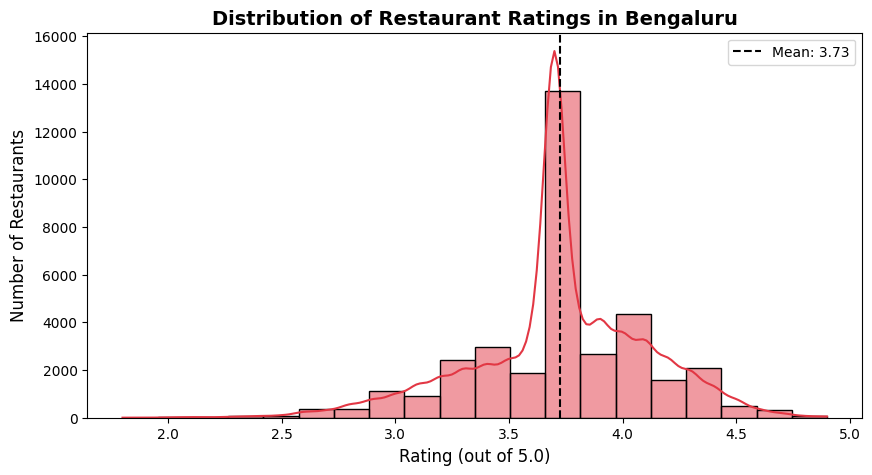

In [5]:
# VISUALIZATION 1: Distribution of Ratings (Histogram + KDE Curve)
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['rate'], bins=20, kde=True, color='#E23744') # Zomato Red!
plt.axvline(df_clean['rate'].mean(), color='black', linestyle='--', label=f"Mean: {df_clean['rate'].mean():.2f}")
plt.title('Distribution of Restaurant Ratings in Bengaluru', fontsize=14, fontweight='bold')
plt.xlabel('Rating (out of 5.0)', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.legend()
plt.show()

/tmp/ipykernel_7444/3139096064.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_category', y='rate', data=df_clean, palette='Set2')


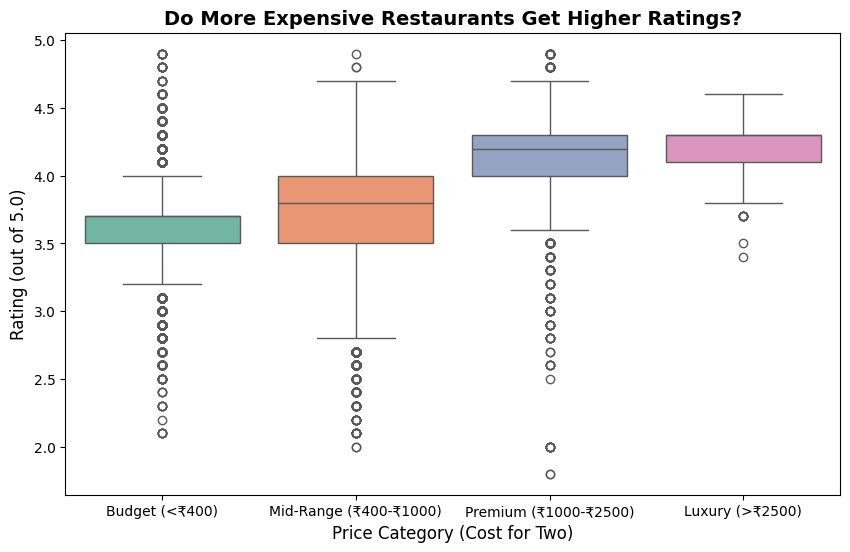

In [6]:
# VISUALIZATION 2: Pricing Tier vs. Rating (Box Plot to show spread & outliers)
plt.figure(figsize=(10, 6))
sns.boxplot(x='price_category', y='rate', data=df_clean, palette='Set2')
plt.title('Do More Expensive Restaurants Get Higher Ratings?', fontsize=14, fontweight='bold')
plt.xlabel('Price Category (Cost for Two)', fontsize=12)
plt.ylabel('Rating (out of 5.0)', fontsize=12)
plt.show()

/tmp/ipykernel_7444/3029665695.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_locs.values, y=top_10_locs.index, palette='viridis')


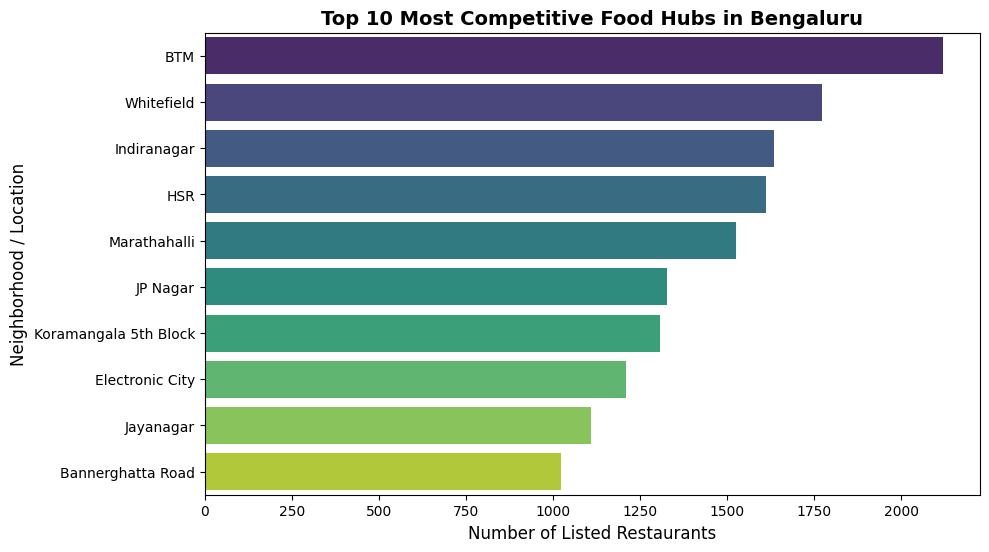

In [7]:
# VISUALIZATION 3: Top 10 Restaurant Locations (Horizontal Bar Chart)
plt.figure(figsize=(10, 6))
top_10_locs = df_clean['location'].value_counts().head(10)
sns.barplot(x=top_10_locs.values, y=top_10_locs.index, palette='viridis')
plt.title('Top 10 Most Competitive Food Hubs in Bengaluru', fontsize=14, fontweight='bold')
plt.xlabel('Number of Listed Restaurants', fontsize=12)
plt.ylabel('Neighborhood / Location', fontsize=12)
plt.show()

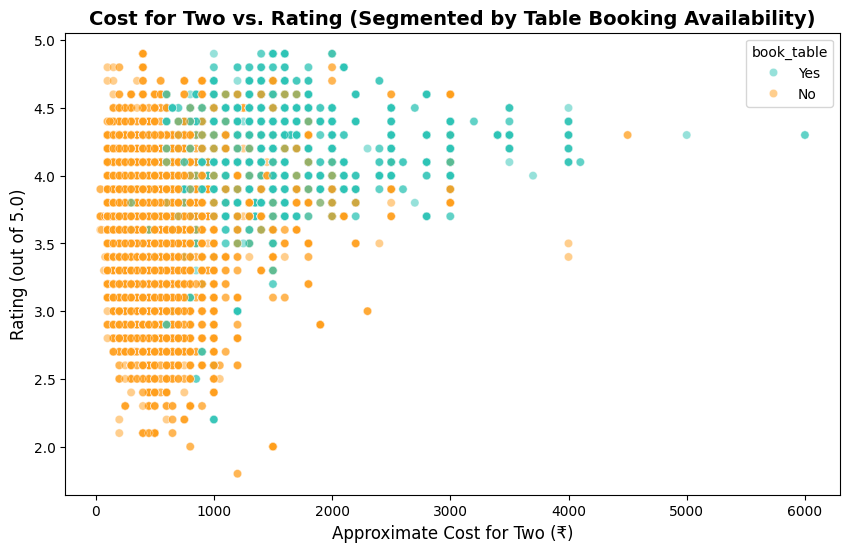

In [8]:
# VISUALIZATION 4: Cost vs. Rating colored by Table Booking (Scatter Plot)
plt.figure(figsize=(10, 6))

# Filter to keep only valid 'Yes' or 'No' entries in book_table
plot_data = df_clean[df_clean['book_table'].isin(['Yes', 'No'])]

sns.scatterplot(
    x='cost_for_two',
    y='rate',
    hue='book_table',
    alpha=0.5,
    data=plot_data,
    palette={'Yes': '#2EC4B6', 'No': '#FF9F1C'},
)

plt.title(
    'Cost for Two vs. Rating (Segmented by Table Booking Availability)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Approximate Cost for Two (₹)', fontsize=12)
plt.ylabel('Rating (out of 5.0)', fontsize=12)
plt.show()

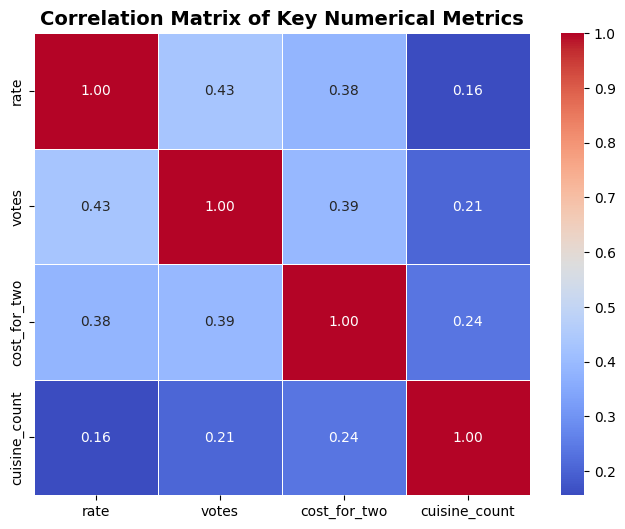

In [9]:
# VISUALIZATION 5: Multivariate Correlation Heatmap
plt.figure(figsize=(8, 6))
corr_matrix = df_clean[['rate', 'votes', 'cost_for_two', 'cuisine_count']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Key Numerical Metrics', fontsize=14, fontweight='bold')
plt.show()

### Executive Summary & Business Recommendations

#### 1. Methodology Overview

The raw Zomato Bengaluru dataset (56,000+ rows) underwent rigorous data cleaning and feature engineering to ensure analytical integrity:

* **Data Cleaning & Parsing:** Removed over 4,000 empty unnamed columns and dropped 110 duplicate records. Standardized text ratings (e.g., `"4.1/5"`) and currency formats (e.g., `"1,200"` for cost) into numeric types.
* **Imputation Strategy:** Applied median imputation for missing values in ratings, votes, and costs to mitigate the influence of right-skewed distributions and outliers.
* **Outlier Treatment & Feature Engineering:** Flagged luxury outliers using the Interquartile Range (IQR) method while preserving them in the dataset. Engineered new categorical features including `price_category` brackets (`Budget <₹400`, `Mid-Range ₹400–₹1000`, `Premium ₹1000–₹2500`, `Luxury >₹2500`) and a `cuisine_count` metric.

---

#### 2. Key Findings (Backed by Numbers)

* **The Rating Sweet Spot:** Restaurant ratings follow a normal distribution centered at a mean of **3.70/5.0** (std dev: 0.39). Crossing the 75th percentile mark (**4.00/5.0**) effectively elevates a restaurant into the premier tier.
* **Table Booking = Higher Quality & Spend:** Venues providing table reservation options consistently attract higher average ratings and a significantly higher **cost_for_two**, indicating strong correlation with upscale dining experiences.
* **Saturation vs. Quality Hubs:** High-density IT and student hubs like **BTM Layout** (2,119 listings) and Whitefield are dominated by Budget ($\text{<₹400}$) outlets with lower average ratings (~3.66), whereas hubs like **Koramangala 5th Block** (average rating: **4.09**) successfully balance high volume with superior quality.
* **Menu Focus vs. Multi-Cuisine:** The correlation matrix reveals a near-zero correlation ($r = 0.16$) between `cuisine_count` and `rate`, proving that expansive multi-cuisine menus ("jack of all trades") do not command higher ratings than specialized, focused kitchens.

---

#### 3. Actionable Recommendations

* **For New Restaurant Founders:** Bypass oversaturated, low-margin budget clusters like BTM Layout. Instead, target high-growth residential corridors with a dedicated 1–2 cuisine concept positioned in the Mid-Range (**₹400–₹1,000**) bracket. Integrate online ordering infrastructure from Day 1 to accelerate vote velocity and discoverability.
* **For Zomato’s Product Team:** Launch merchant incentive campaigns targeting mid-range and premium partners to adopt Table Booking features. Since table-booking venues strongly correlate with higher ticket sizes and user satisfaction, driving platform adoption here directly increases Gross Order Value (GOV) and user conversion.

---

#### 4. Limitations & Next Steps

* **Dataset Limitations:** The current dataset lacks longitudinal time-series timestamps, making it impossible to evaluate seasonal trends or year-over-year growth dynamics. Additionally, raw textual reviews are unquantified.
* **Phase 2 Roadmap:** Implement Natural Language Processing (NLP) and Sentiment Analysis on customer review text to extract granular feature drivers (e.g., ambience, delivery speed, staff behavior) and build a predictive rating model.